# Challenge 4: Quantum Correlation Switch

## Aim and predictions

The aim is to make two versions of a circuit: one where the measured bits match
and one where they are opposite. I use H and CNOT to make a Bell state, then use
an optional X gate on q0 as the switch.

| Part | X gate on q0 after CNOT? | Prediction before running |
| --- | --- | --- |
| A: Correlated outcomes | No | Only `00` and `11`, roughly 50 of each in 100 shots |
| B: Opposite outcomes | Yes | Only `01` and `10`, roughly 50 of each in 100 shots |

I do not expect all four outcomes in either experiment on the ideal simulator.
In each circuit, two outcomes have probability 1/2 and the other two have
probability zero. The two allowed counts can still differ because measurement
is random.

## Setup

I used Qiskit's `BasicSimulator` to run the circuits on an ideal local simulator.
These are simulator results, not results from a real quantum computer.
If the packages are missing, uncomment the installation line below, run it,
and restart the kernel. Then run the notebook from the top.

In [1]:
# %pip install qiskit matplotlib pylatexenc

In [2]:
import qiskit
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from qiskit import QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

shots = 100
seed = 2026
simulator = BasicSimulator()
print("Qiskit version:", qiskit.__version__)
print("Shots for each circuit:", shots)

Qiskit version: 2.5.2
Shots for each circuit: 100


## 1. Build the correlation switch

Here, `opposite=False` builds Part A and `opposite=True` builds Part B.
This is just a Python setting that chooses whether to add X before running
the circuit.


Qiskit starts both qubits in $|00\rangle$. I measure `q0` into `c0` and
`q1` into `c1`. The output strings are written as **c1c0** (or **q1q0** here),
so `01` means q1 is 0 and q0 is 1. Both `00` and `11` have matching bits;
both `01` and `10` have opposite bits.


Part A uses 2 quantum gates (H and CNOT). Part B uses 3 (H, CNOT and X).
Both circuits measure the two qubits and use fewer than 4 quantum gates.

Part A: correlated


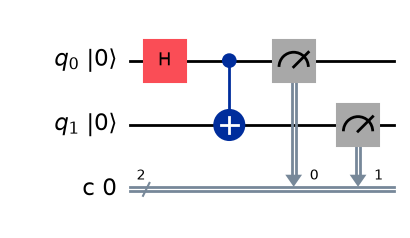

Part B: opposite


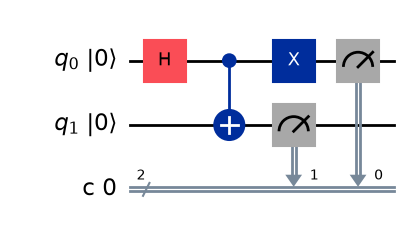

In [3]:
def make_circuit(opposite=False):
    name = "Part B: opposite" if opposite else "Part A: correlated"
    circuit = QuantumCircuit(2, 2, name=name)
    circuit.h(0)
    circuit.cx(0, 1)

    if opposite:
        circuit.x(0)  # Flip one qubit to change the correlation.

    circuit.measure([0, 1], [0, 1])
    return circuit

circuit_a = make_circuit(opposite=False)
circuit_b = make_circuit(opposite=True)

for circuit in [circuit_a, circuit_b]:
    print(circuit.name)
    fig = circuit.draw("mpl", initial_state=True)
    display(fig)
    plt.close(fig)

## 2. Part A and Part B: run 100 shots each

The simulator runs each circuit from the initial state again for every shot.
I set a random seed to make the example reproducible with the same software
version. Changing it, or using `seed = None`, can change the sampled counts.

In [4]:
counts_a = simulator.run(
    circuit_a, shots=shots, seed_simulator=seed
).result().get_counts()

counts_b = simulator.run(
    circuit_b, shots=shots, seed_simulator=seed
).result().get_counts()

print("Part A:", counts_a)
print("Part B:", counts_b)

Part A: {'00': 49, '11': 51}
Part B: {'01': 49, '10': 51}


## 3. Part C: compare the histograms

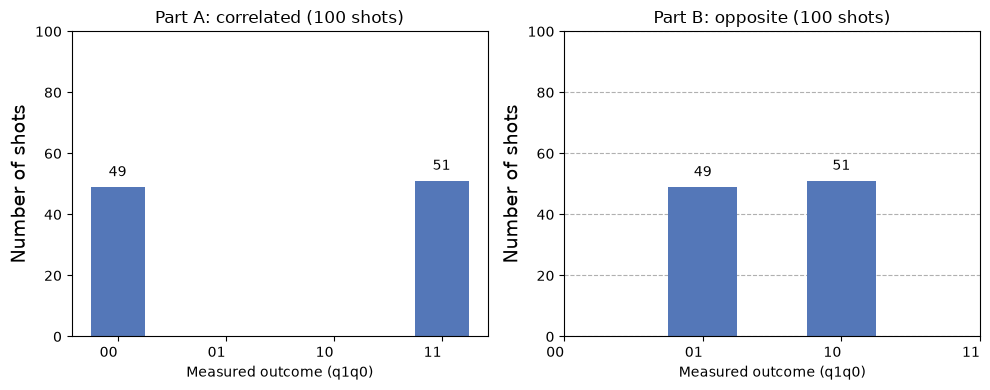

In [5]:
# Show all four possible outcomes, including the ones with zero counts.
outcomes = ["00", "01", "10", "11"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, title, result_counts in zip(
    axes, ['Part A: correlated (100 shots)', 'Part B: opposite (100 shots)'], [counts_a, counts_b]
):
    all_counts = {bit: result_counts.get(bit, 0) for bit in outcomes}
    plot_histogram(all_counts, ax=ax, color="#5477B8")
    ax.set_title(title)
    ax.set_xlabel("Measured outcome (q1q0)")
    ax.set_ylabel("Number of shots")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", labelrotation=0)
fig.tight_layout()
display(fig)
plt.close(fig)

In [6]:
table = "| Outcome | Part A count | Part B count |\n| --- | ---: | ---: |\n"
for outcome in ["00", "01", "10", "11"]:
    table += f"| {outcome} | {counts_a.get(outcome, 0)} | {counts_b.get(outcome, 0)} |\n"
display(Markdown(table))

same_a = counts_a.get("00", 0) + counts_a.get("11", 0)
same_b = counts_b.get("00", 0) + counts_b.get("11", 0)
opposite_a = counts_a.get("01", 0) + counts_a.get("10", 0)
opposite_b = counts_b.get("01", 0) + counts_b.get("10", 0)
print(f"Part A: {same_a} matching pairs, {opposite_a} opposite pairs")
print(f"Part B: {same_b} matching pairs, {opposite_b} opposite pairs")

| Outcome | Part A count | Part B count |
| --- | ---: | ---: |
| 00 | 49 | 0 |
| 01 | 0 | 49 |
| 10 | 0 | 51 |
| 11 | 51 | 0 |


Part A: 100 matching pairs, 0 opposite pairs
Part B: 0 matching pairs, 100 opposite pairs


## 4. Explanation

**Which outcomes dominate in Part A?**
`00` and `11` are the only outcomes in the ideal result. The H and CNOT gates
prepare the state

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}.$$

This means the measured bits always match, although either pair can be obtained.

**Which outcomes dominate in Part B?**
`01` and `10` are the only outcomes. The state becomes

$$|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}.$$

**What changed between the circuits?**
I added one X gate on q0 after the CNOT and before measurement. Everything else
stayed the same.

**Why did the measurement relationship change?**
X flips q0 but leaves q1 alone. Using Qiskit's q1q0 ordering,
`00` changes to `01` and `11` changes to `10`. So matching pairs become opposite
pairs. Each qubit still has a 50% chance of being 0 or 1; the relationship between
the two bits has changed. Both states are entangled.

**Do the results match the predictions?**
Yes. Part A has only matching pairs and Part B has only opposite pairs.
The two allowed outcomes are close to a 50-50 split. They do not have to occur
exactly 50 times each because 100 shots is a finite random sample.

## 5. Quick check

In [7]:
for circuit, counts in [(circuit_a, counts_a), (circuit_b, counts_b)]:
    assert circuit.num_qubits == 2
    assert circuit.count_ops().get("measure", 0) == 2
    assert set(circuit.count_ops()) <= {"h", "cx", "x", "measure"}
    gate_count = sum(circuit.count_ops().values()) - 2
    assert gate_count <= 4
    assert sum(counts.values()) == 100

assert dict(circuit_a.count_ops()) == {"h": 1, "cx": 1, "measure": 2}
assert dict(circuit_b.count_ops()) == {"h": 1, "cx": 1, "x": 1, "measure": 2}
assert same_a == 100 and opposite_a == 0
assert same_b == 0 and opposite_b == 100
print("Checks passed: both parts use two qubits, measure both, and run for 100 shots.")

Checks passed: both parts use two qubits, measure both, and run for 100 shots.


## Conclusion

The optional X gate works as a correlation switch. Leaving it out gives
matching bits, while adding it gives opposite bits. Only three quantum gates
are needed for the opposite-outcome circuit, so the design meets the gate limit.

*Problem source: the supplied Challenge 4 PDF, Qiskit Fall Fest 2026.*